<a href="https://colab.research.google.com/github/Ofifah1063/tebu-classifier/blob/main/Sugarcane_Leaf_Disease_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
nirmalsankalana_sugarcane_leaf_disease_dataset_path = kagglehub.dataset_download('nirmalsankalana/sugarcane-leaf-disease-dataset')

print('Data source import complete.')


Using Colab cache for faster access to the 'sugarcane-leaf-disease-dataset' dataset.
Data source import complete.


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import tensorflow as tf
from tensorflow import keras

In [3]:
dataset= "/kaggle/input/sugarcane-leaf-disease-dataset"

In [4]:
train = tf.keras.preprocessing.image_dataset_from_directory(
    nirmalsankalana_sugarcane_leaf_disease_dataset_path,
    labels="inferred",
    batch_size=40,
    image_size=(128,128),
    shuffle=True,
    seed=42,
    validation_split=0.2,
    subset="training"
)

test = tf.keras.preprocessing.image_dataset_from_directory(
    nirmalsankalana_sugarcane_leaf_disease_dataset_path,
    labels="inferred",
    batch_size=40,
    image_size=(128,128),
    seed=42,
    validation_split=0.2,
    subset="validation"
)

Found 2521 files belonging to 5 classes.
Using 2017 files for training.
Found 2521 files belonging to 5 classes.
Using 504 files for validation.


In [5]:
cat=train.class_names
cat

['Healthy', 'Mosaic', 'RedRot', 'Rust', 'Yellow']

In [6]:
for example_image, example_label in train.take(1):
  break

print(f"Image Shape: {example_image.shape}")

Image Shape: (40, 128, 128, 3)


In [7]:
validation_ds = test.shard(num_shards=2, index=0)
test_ds = test.shard(num_shards=2, index=1)

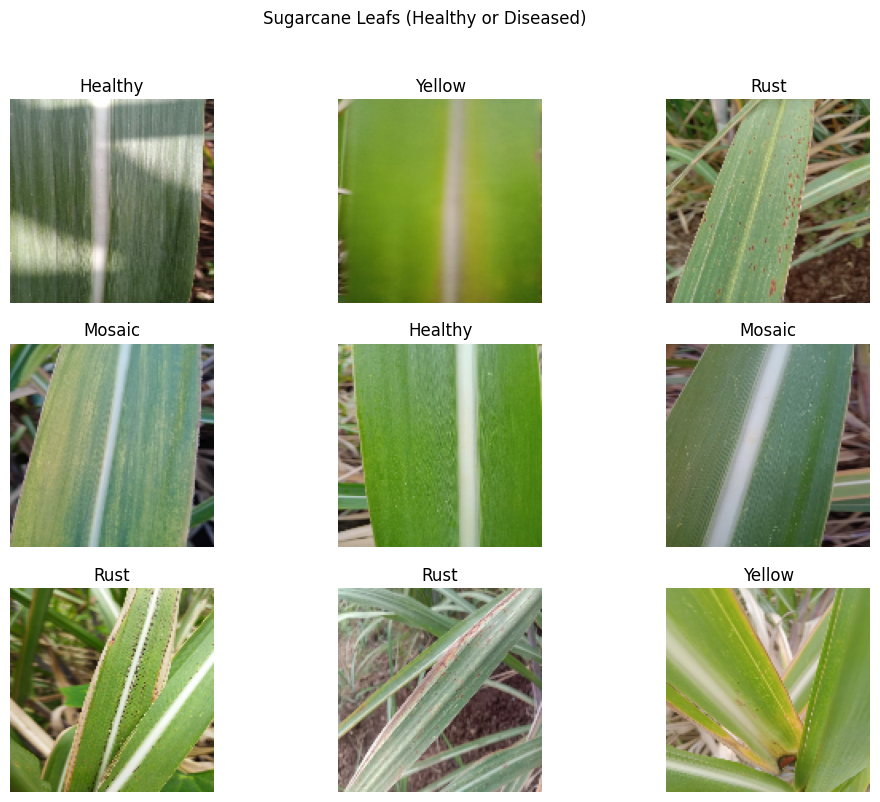

In [8]:
plt.figure(figsize=(12, 9))
for images, labels in train.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(cat[labels[i]])
        plt.suptitle("Sugarcane Leafs (Healthy or Diseased)")
        plt.axis("off")

In [9]:
train_ds = train.cache().shuffle(250).prefetch(buffer_size=tf.data.AUTOTUNE)
validation_ds = validation_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)

In [10]:
base_model = tf.keras.applications.ResNet152V2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = True

print(len(base_model.layers))

564


In [11]:
for layer in base_model.layers[:125]:
  layer.trainable = False

In [12]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Rescaling(1./255),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Dense(len(cat))
])

In [13]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

In [14]:
history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=30,
)

Epoch 1/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 244s 2s/step - accuracy: 0.2157 - loss: 1.6939 - val_accuracy: 0.1818 - val_loss: 1.6099
Epoch 2/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 15s 287ms/step - accuracy: 0.2231 - loss: 1.6085 - val_accuracy: 0.1818 - val_loss: 1.6109
Epoch 3/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 15s 290ms/step - accuracy: 0.2221 - loss: 1.6083 - val_accuracy: 0.1818 - val_loss: 1.6102
Epoch 4/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 14s 272ms/step - accuracy: 0.2142 - loss: 1.6091 - val_accuracy: 0.1818 - val_loss: 1.6078
Epoch 5/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 13s 263ms/step - accuracy: 0.2058 - loss: 1.6088 - val_accuracy: 0.1818 - val_loss: 1.6073
Epoch 6/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 14s 266ms/step - accuracy: 0.2157 - loss: 1.6073 - val_accuracy: 0.2462 - val_loss: 1.6049
Epoch 7/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 14s 268ms/step - accuracy: 0.2424 - loss: 1.6056 - val_accuracy: 0.2500 - val_loss: 1.6016
Epoch 8/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 14s 271ms/step - accuracy: 0.2196 - loss: 1.6100 - val_accura

In [15]:
import time
start = time.time()
history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=30
)
print("Waktu training:", time.time() - start, "detik")

Epoch 1/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 14s 275ms/step - accuracy: 0.5191 - loss: 0.9344 - val_accuracy: 0.3939 - val_loss: 1.4870
Epoch 2/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 14s 275ms/step - accuracy: 0.5508 - loss: 0.9060 - val_accuracy: 0.4053 - val_loss: 1.2923
Epoch 3/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 14s 275ms/step - accuracy: 0.5250 - loss: 0.9271 - val_accuracy: 0.2462 - val_loss: 1.8607
Epoch 4/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 14s 275ms/step - accuracy: 0.5617 - loss: 0.8685 - val_accuracy: 0.4129 - val_loss: 1.2360
Epoch 5/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 14s 277ms/step - accuracy: 0.5959 - loss: 0.8259 - val_accuracy: 0.4848 - val_loss: 1.2425
Epoch 6/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 14s 275ms/step - accuracy: 0.5984 - loss: 0.8081 - val_accuracy: 0.4811 - val_loss: 1.5340
Epoch 7/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 14s 275ms/step - accuracy: 0.6306 - loss: 0.7915 - val_accuracy: 0.4432 - val_loss: 1.5319
Epoch 8/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 14s 275ms/step - accuracy: 0.6510 - loss: 0.7309 - val_accu

In [16]:
import tensorflow as tf
from tensorflow.keras import layers, models

base = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights="imagenet")
base.trainable = False  # bekukan dulu, jangan ikut dilatih

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Resizing(224, 224),            # Ubah ukuran gambar secara dinamis ke 224x224
    layers.RandomFlip("horizontal"),      # augmentasi
    layers.RandomRotation(0.1),
    layers.Rescaling(1./127.5, offset=-1),  # normalisasi khusus MobileNetV2
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(len(cat), activation="softmax")
])

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",  # sesuaikan label_mode
              metrics=["accuracy"])

In [17]:
# Dynamically resize datasets to 224x224 to match the expected model input
train_ds_resized = train_ds.map(lambda x, y: (tf.image.resize(x, (224, 224)), y))
validation_ds_resized = validation_ds.map(lambda x, y: (tf.image.resize(x, (224, 224)), y))

es = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True)

history = model.fit(train_ds_resized, validation_data=validation_ds_resized,
                    epochs=50, callbacks=[es])

Epoch 1/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 18s 176ms/step - accuracy: 0.4398 - loss: 1.3705 - val_accuracy: 0.7348 - val_loss: 0.8368
Epoch 2/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 12s 88ms/step - accuracy: 0.6450 - loss: 0.9028 - val_accuracy: 0.8220 - val_loss: 0.6505
Epoch 3/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 81ms/step - accuracy: 0.6991 - loss: 0.7652 - val_accuracy: 0.8106 - val_loss: 0.5518
Epoch 4/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 81ms/step - accuracy: 0.7377 - loss: 0.7041 - val_accuracy: 0.8447 - val_loss: 0.5035
Epoch 5/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 88ms/step - accuracy: 0.7630 - loss: 0.6230 - val_accuracy: 0.8485 - val_loss: 0.4769
Epoch 6/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 82ms/step - accuracy: 0.7814 - loss: 0.5843 - val_accuracy: 0.8598 - val_loss: 0.4474
Epoch 7/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 83ms/step - accuracy: 0.7918 - loss: 0.5601 - val_accuracy: 0.8561 - val_loss: 0.4310
Epoch 8/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 4s 88ms/step - accuracy: 0.8141 - loss: 0.5206 - val_accuracy: 0.8598 